<a href="https://colab.research.google.com/github/Lakshmi1477/Recurring_Drift_Research/blob/main/Recurring_Concept_Drift_Pilot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
%pip install -q "river>=0.22,<0.24" numpy pandas matplotlib scikit-learn
import river
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("River version:", river.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Research environment is ready!")

River version: 0.23.0
NumPy version: 2.1.3
Pandas version: 2.2.3
Research environment is ready!


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducibility: the same data each time
rng = np.random.default_rng(42)

def generate_sea_segment(n, concept, rng):
    """Generate one SEA concept segment."""
    X = rng.random((n, 3)) * 10

    # SEA concepts use two features for classification
    thresholds = {
        "A": 8,
        "B": 9,
        "C": 7
    }

    y = ((X[:, 0] + X[:, 1]) > thresholds[concept]).astype(int)

    # Add a small amount of classification noise
    noise = rng.random(n) < 0.05
    y[noise] = 1 - y[noise]

    return X, y

# Concept A → Concept B → Concept A returns
segment_size = 1000
concept_sequence = ["A", "B", "A"]

X_parts = []
y_parts = []
concept_labels = []

for concept in concept_sequence:
    X_part, y_part = generate_sea_segment(
        segment_size, concept, rng
    )
    X_parts.append(X_part)
    y_parts.append(y_part)
    concept_labels.extend([concept] * segment_size)

X = np.vstack(X_parts)
y = np.concatenate(y_parts)

data = pd.DataFrame(X, columns=["x1", "x2", "x3"])
data["label"] = y
data["concept"] = concept_labels

print("Dataset shape:", data.shape)
print("\nConcept distribution:")
print(data["concept"].value_counts())
print("\nFirst five rows:")
display(data.head())

Dataset shape: (3000, 5)

Concept distribution:
concept
A    2000
B    1000
Name: count, dtype: int64

First five rows:


,x1,x2,x3,label,concept
0,7.739560,4.388784,8.585979,1,A
1,6.973680,0.941773,9.756224,0,A
2,7.611397,7.860643,1.281136,1,A
3,4.503859,3.707980,9.267650,1,A
4,6.438651,8.227616,4.434142,1,A


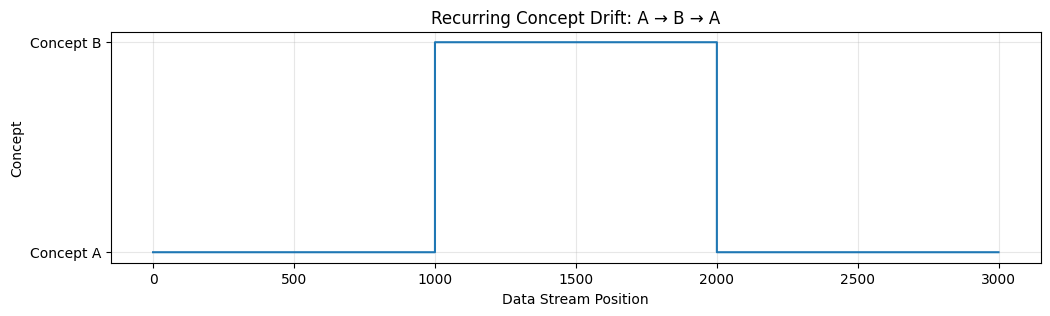

In [6]:
plt.figure(figsize=(12, 3))

concept_to_number = {"A": 0, "B": 1}

concept_numbers = data["concept"].map(concept_to_number)

plt.plot(
    np.arange(len(data)),
    concept_numbers,
    drawstyle="steps-post"
)

plt.xlabel("Data Stream Position")
plt.ylabel("Concept")
plt.title("Recurring Concept Drift: A → B → A")
plt.yticks([0, 1], ["Concept A", "Concept B"])
plt.grid(True, alpha=0.3)
plt.show()

In [7]:
from river import naive_bayes
from river import metrics

def run_fixed_budget(X, y, budget_rate=0.10):
    model = naive_bayes.GaussianNB()
    metric = metrics.Accuracy()

    rng = np.random.default_rng(42)
    queried_labels = 0
    predictions = []

    for i in range(len(X)):
        x = {
            "x1": float(X[i, 0]),
            "x2": float(X[i, 1]),
            "x3": float(X[i, 2])
        }

        # Predict before using the current label
        prediction = model.predict_one(x)
        if prediction is None:
            prediction = 0

        predictions.append(prediction)

        # Simulate whether this label is available
        if rng.random() < budget_rate:
            label = int(y[i])
            metric.update(label, prediction)
            model.learn_one(x, label)
            queried_labels += 1

    return {
        "accuracy_on_queried_labels": metric.get(),
        "queried_labels": queried_labels,
        "total_samples": len(X),
        "actual_label_rate": queried_labels / len(X),
        "predictions": predictions
    }

fixed_results = run_fixed_budget(X, y)

print("Fixed-budget baseline results")
print("--------------------------------")
print("Total samples:", fixed_results["total_samples"])
print("Labels queried:", fixed_results["queried_labels"])
print("Actual label rate:",
      round(fixed_results["actual_label_rate"] * 100, 2), "%")
print("Accuracy on queried labels:",
      round(fixed_results["accuracy_on_queried_labels"], 4))

Fixed-budget baseline results
--------------------------------
Total samples: 3000
Labels queried: 294
Actual label rate: 9.8 %
Accuracy on queried labels: 0.8844
